# Belirti → Hastalık – Modelleme
**Veri akışı:** silver (temiz metin) → **gold** (eğitim/test ayrımı) → TF-IDF → modeller
Problem: 24 sınıflı metin sınıflandırma.

In [1]:
import os, sys, warnings
os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

sys.path.append("../src")
from metin_isleme import temizle, toplu_temizle

sns.set_theme(style="whitegrid")
FIG = "../results/figures/"
TAB = "../results/tables/"
SEED = 42

In [2]:
silver = pd.read_csv("../data/silver/symptom_silver.csv")
print("Boyut:", silver.shape, "| Hastalık sayısı:", silver["label"].nunique())
silver.head(3)

Boyut: (1153, 3) | Hastalık sayısı: 24


,label,text,temiz_metin
0,Psoriasis,I have been experiencing a skin rash on my arm...,experiencing skin rash arm leg torso past week...
1,Psoriasis,"My skin has been peeling, especially on my kne...",skin peeling especially knee elbow scalp peeli...
2,Psoriasis,I have been experiencing joint pain in my fing...,experiencing joint pain finger wrist knee pain...


## Gold katmanı
Veri %80 eğitim / %20 test olarak, her hastalığın oranı korunarak ayrılır.
TF-IDF dönüşümü gold'a yazılmaz; pipeline içinde **sadece eğitim verisinden** öğrenilir (kelime listesi ve IDF ağırlıkları test verisinden etkilenmesin diye).

In [3]:
X = silver["temiz_metin"]
y = silver["label"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

pd.DataFrame({"temiz_metin": X_train, "label": y_train}).to_csv("../data/gold/symptom_train.csv", index=False)
pd.DataFrame({"temiz_metin": X_test, "label": y_test}).to_csv("../data/gold/symptom_test.csv", index=False)
print("Eğitim:", len(X_train), " Test:", len(X_test))

Eğitim: 922  Test: 231


In [4]:
ornek_tfidf = TfidfVectorizer().fit(X_train)
print("Eğitim verisindeki farklı kelime sayısı (vektör boyutu):", len(ornek_tfidf.vocabulary_))

vektor = ornek_tfidf.transform([X_train.iloc[0]])
agirliklar = pd.Series(vektor.toarray()[0], index=ornek_tfidf.get_feature_names_out())
print("\nMetin:", X_train.iloc[0])
print("\nEn yüksek ağırlıklı 8 kelime:")
print(agirliklar.sort_values(ascending=False).head(8).round(3))

Eğitim verisindeki farklı kelime sayısı (vektör boyutu): 1271

Metin: skin rash red swollen spreading body mild fever causing lot discomfort

En yüksek ağırlıklı 8 kelime:
spreading     0.437
mild          0.382
causing       0.341
swollen       0.327
body          0.292
discomfort    0.290
red           0.278
rash          0.246
dtype: float64


## Kullanılan algoritmalar
| Model | Neden seçildi? |
|---|---|
| Lojistik Regresyon | Metin sınıflandırmada güçlü ve hızlı temel model |
| Doğrusal SVM | Yüksek boyutlu, seyrek TF-IDF vektörlerinde literatürde en başarılı yöntemlerden |
| Multinomial Naive Bayes | Kelime sıklıklarına dayalı klasik metin sınıflandırıcı |
| KNN (kosinüs) | En benzer metinlere bakar; kosinüs benzerliği metinler için uygun |
| Random Forest | Ağaç tabanlı topluluk yöntemi, karşılaştırma için |
| Yapay Sinir Ağı (MLP) | Derin öğrenme temsilcisi; doğrusal olmayan ilişkileri öğrenebilir |

**Metrikler:** 24 sınıf olduğu için Precision, Recall ve F1 her hastalık için ayrı hesaplanıp ortalaması alınır (macro). ROC-AUC her hastalık için "bu hastalık mı, değil mi" şeklinde hesaplanıp ortalanır (one-vs-rest).

In [5]:
modeller = {
    "Lojistik Regresyon": LogisticRegression(max_iter=2000, random_state=SEED),
    "SVM (doğrusal)": SVC(kernel="linear", probability=True, random_state=SEED),
    "Naive Bayes": MultinomialNB(),
    "KNN": KNeighborsClassifier(metric="cosine"),
    "Random Forest": RandomForestClassifier(random_state=SEED, n_jobs=-1),
    "Yapay Sinir Ağı (MLP)": MLPClassifier(max_iter=300, random_state=SEED),
}

def model_kur(algoritma):
    return Pipeline([("tfidf", TfidfVectorizer()), ("model", algoritma)])

def metrikler(model, X, y):
    tahmin = model.predict(X)
    olasilik = model.predict_proba(X)
    return {"Accuracy": accuracy_score(y, tahmin),
            "Precision": precision_score(y, tahmin, average="macro", zero_division=0),
            "Recall": recall_score(y, tahmin, average="macro", zero_division=0),
            "F1-Score": f1_score(y, tahmin, average="macro", zero_division=0),
            "ROC-AUC": roc_auc_score(y, olasilik, multi_class="ovr", average="macro", labels=model.classes_)}

temel = {ad: metrikler(model_kur(alg).fit(X_train, y_train), X_test, y_test) for ad, alg in modeller.items()}
temel_df = pd.DataFrame(temel).T.round(4).sort_values("F1-Score", ascending=False)
temel_df.to_csv(TAB + "belirti_temel_sonuclar.csv")
temel_df

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
SVM (doğrusal),0.9697,0.9752,0.9708,0.9707,0.9996
Yapay Sinir Ağı (MLP),0.9697,0.9729,0.9708,0.9703,0.9996
Random Forest,0.9567,0.9632,0.9579,0.9570,0.9989
Lojistik Regresyon,0.9437,0.9501,0.9454,0.9437,0.9986
Naive Bayes,0.9394,0.9458,0.9417,0.9382,0.9982
KNN,0.9264,0.9329,0.9287,0.9276,0.9982


## Hiperparametre optimizasyonu
Hem model ayarları hem de TF-IDF ayarı birlikte aranır:
- `ngram_range=(1,1)`: sadece tek kelimeler ("chest", "pain")
- `ngram_range=(1,2)`: kelime ikilileri de ("chest pain") – birlikte geçen kelimelerin anlamını yakalar
5 katlı çapraz doğrulama, kriter: macro F1.

In [6]:
NGRAM = [(1, 1), (1, 2)]
izgaralar = {
    "Lojistik Regresyon": {"tfidf__ngram_range": NGRAM, "model__C": [1, 10, 100]},
    "SVM (doğrusal)": {"tfidf__ngram_range": NGRAM, "model__C": [0.1, 1, 10]},
    "Naive Bayes": {"tfidf__ngram_range": NGRAM, "model__alpha": [0.01, 0.1, 0.5, 1.0]},
    "KNN": {"tfidf__ngram_range": NGRAM, "model__n_neighbors": [1, 3, 5, 7, 11],
            "model__weights": ["uniform", "distance"]},
    "Random Forest": {"tfidf__ngram_range": NGRAM, "model__n_estimators": [300],
                      "model__max_depth": [None, 50], "model__min_samples_leaf": [1, 2]},
    "Yapay Sinir Ağı (MLP)": {"tfidf__ngram_range": NGRAM, "model__hidden_layer_sizes": [(128,), (256, 128)],
                              "model__alpha": [0.0001, 0.01]},
}

In [7]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
en_iyi_modeller, secilen = {}, []
for ad, alg in modeller.items():
    arama = GridSearchCV(model_kur(alg), izgaralar[ad], scoring="f1_macro", cv=cv5, n_jobs=-1).fit(X_train, y_train)
    en_iyi_modeller[ad] = arama.best_estimator_
    p = {k.split("__")[1]: v for k, v in arama.best_params_.items()}
    secilen.append({"Model": ad, "Seçilen ayarlar": p, "CV macro-F1": round(arama.best_score_, 4)})
    print(f"{ad:24s} CV F1 = {arama.best_score_:.4f}  {p}")
pd.DataFrame(secilen).to_csv(TAB + "belirti_secilen_hiperparametreler.csv", index=False)

Lojistik Regresyon       CV F1 = 0.9700  {'C': 100, 'ngram_range': (1, 1)}
SVM (doğrusal)           CV F1 = 0.9724  {'C': 10, 'ngram_range': (1, 2)}
Naive Bayes              CV F1 = 0.9699  {'alpha': 0.01, 'ngram_range': (1, 2)}
KNN                      CV F1 = 0.9514  {'n_neighbors': 3, 'weights': 'distance', 'ngram_range': (1, 1)}
Random Forest            CV F1 = 0.9500  {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 300, 'ngram_range': (1, 1)}
Yapay Sinir Ağı (MLP)    CV F1 = 0.9690  {'alpha': 0.01, 'hidden_layer_sizes': (128,), 'ngram_range': (1, 2)}


In [8]:
opt_df = pd.DataFrame({ad: metrikler(m, X_test, y_test) for ad, m in en_iyi_modeller.items()}).T.round(4)
opt_df = opt_df.sort_values("F1-Score", ascending=False)
opt_df.to_csv(TAB + "belirti_optimize_sonuclar.csv")

karsilastirma = pd.DataFrame({"F1 (varsayılan)": temel_df["F1-Score"], "F1 (optimize)": opt_df["F1-Score"]}).loc[opt_df.index]
karsilastirma["Fark"] = (karsilastirma["F1 (optimize)"] - karsilastirma["F1 (varsayılan)"]).round(4)
karsilastirma.to_csv(TAB + "belirti_optimizasyon_etkisi.csv")
display(opt_df); display(karsilastirma)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Lojistik Regresyon,0.9740,0.9761,0.9750,0.9747,0.9998
SVM (doğrusal),0.9654,0.9717,0.9667,0.9660,0.9999
Yapay Sinir Ağı (MLP),0.9654,0.9717,0.9667,0.9660,0.9997
KNN,0.9567,0.9633,0.9583,0.9578,0.9977
Naive Bayes,0.9524,0.9581,0.9542,0.9526,0.9997
Random Forest,0.9437,0.9503,0.9454,0.9438,0.9990


,F1 (varsayılan),F1 (optimize),Fark
Lojistik Regresyon,0.9437,0.9747,0.0310
SVM (doğrusal),0.9707,0.9660,-0.0047
Yapay Sinir Ağı (MLP),0.9703,0.9660,-0.0043
KNN,0.9276,0.9578,0.0302
Naive Bayes,0.9382,0.9526,0.0144
Random Forest,0.9570,0.9438,-0.0132


In [9]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
skorlar = {"Accuracy": "accuracy", "Precision": "precision_macro", "Recall": "recall_macro",
           "F1-Score": "f1_macro", "ROC-AUC": "roc_auc_ovr"}
cv_tablo, cv_f1 = {}, {}
for ad, m in en_iyi_modeller.items():
    s = cross_validate(m, X, y, cv=rcv, scoring=skorlar, n_jobs=-1)
    cv_f1[ad] = s["test_F1-Score"]
    cv_tablo[ad] = {k: f"{s['test_' + k].mean():.3f} ± {s['test_' + k].std():.3f}" for k in skorlar}
cv_df = pd.DataFrame(cv_tablo).T.loc[opt_df.index]
cv_df.to_csv(TAB + "belirti_tekrarli_cv.csv")
cv_df

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Lojistik Regresyon,0.981 ± 0.010,0.983 ± 0.008,0.982 ± 0.009,0.981 ± 0.009,1.000 ± 0.000
SVM (doğrusal),0.982 ± 0.010,0.984 ± 0.009,0.982 ± 0.009,0.982 ± 0.010,1.000 ± 0.000
Yapay Sinir Ağı (MLP),0.979 ± 0.011,0.981 ± 0.010,0.980 ± 0.011,0.979 ± 0.011,1.000 ± 0.000
KNN,0.969 ± 0.013,0.973 ± 0.012,0.970 ± 0.013,0.969 ± 0.013,0.995 ± 0.003
Naive Bayes,0.979 ± 0.007,0.981 ± 0.006,0.980 ± 0.007,0.979 ± 0.007,1.000 ± 0.000
Random Forest,0.963 ± 0.014,0.967 ± 0.013,0.964 ± 0.013,0.963 ± 0.014,0.999 ± 0.001


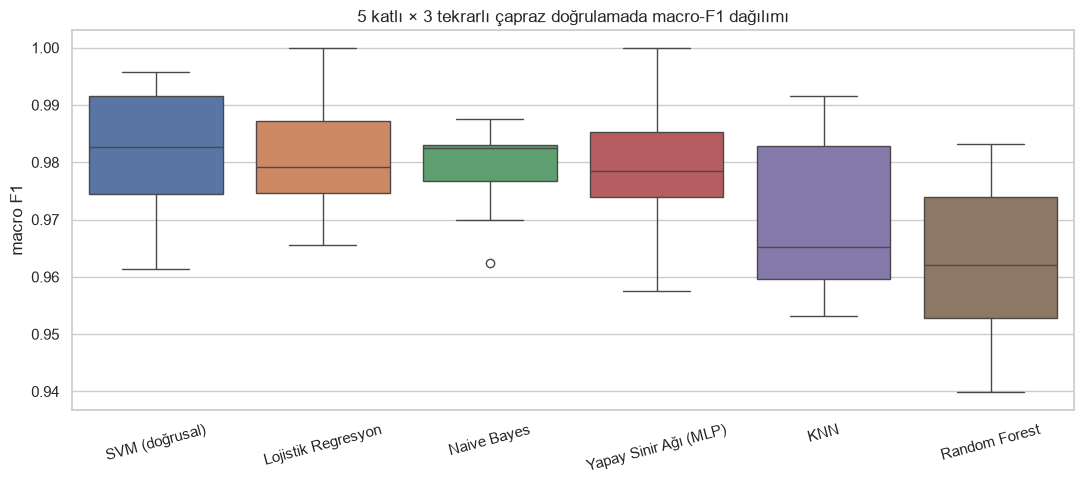

Seçilen model: SVM (doğrusal)


,Karşılaştırma,Ortalama fark,p-değeri,Anlamlı mı?
0,SVM (doğrusal) vs Lojistik Regresyon,0.0008,0.9773,Hayır
1,SVM (doğrusal) vs Naive Bayes,0.0028,0.2769,Hayır
2,SVM (doğrusal) vs Yapay Sinir Ağı (MLP),0.0029,0.1670,Hayır
3,SVM (doğrusal) vs KNN,0.0126,0.0054,Evet
4,SVM (doğrusal) vs Random Forest,0.0190,0.0001,Evet


In [10]:
from scipy.stats import wilcoxon

sirali = sorted(cv_f1, key=lambda a: -cv_f1[a].mean())
plt.figure(figsize=(11, 5))
sns.boxplot(data=[cv_f1[a] for a in sirali])
plt.xticks(range(len(sirali)), sirali, rotation=15); plt.ylabel("macro F1")
plt.title("5 katlı × 3 tekrarlı çapraz doğrulamada macro-F1 dağılımı")
plt.tight_layout(); plt.savefig(FIG + "belirti_04_cv_kutu.png", dpi=150); plt.show()

final_ad = sirali[0]
test = [{"Karşılaştırma": f"{final_ad} vs {ad}",
         "Ortalama fark": round(cv_f1[final_ad].mean() - cv_f1[ad].mean(), 4),
         "p-değeri": round(wilcoxon(cv_f1[final_ad], cv_f1[ad]).pvalue, 4)} for ad in sirali[1:]]
test_df = pd.DataFrame(test); test_df["Anlamlı mı?"] = np.where(test_df["p-değeri"] < 0.05, "Evet", "Hayır")
test_df.to_csv(TAB + "belirti_istatistiksel_test.csv", index=False)
print("Seçilen model:", final_ad); test_df

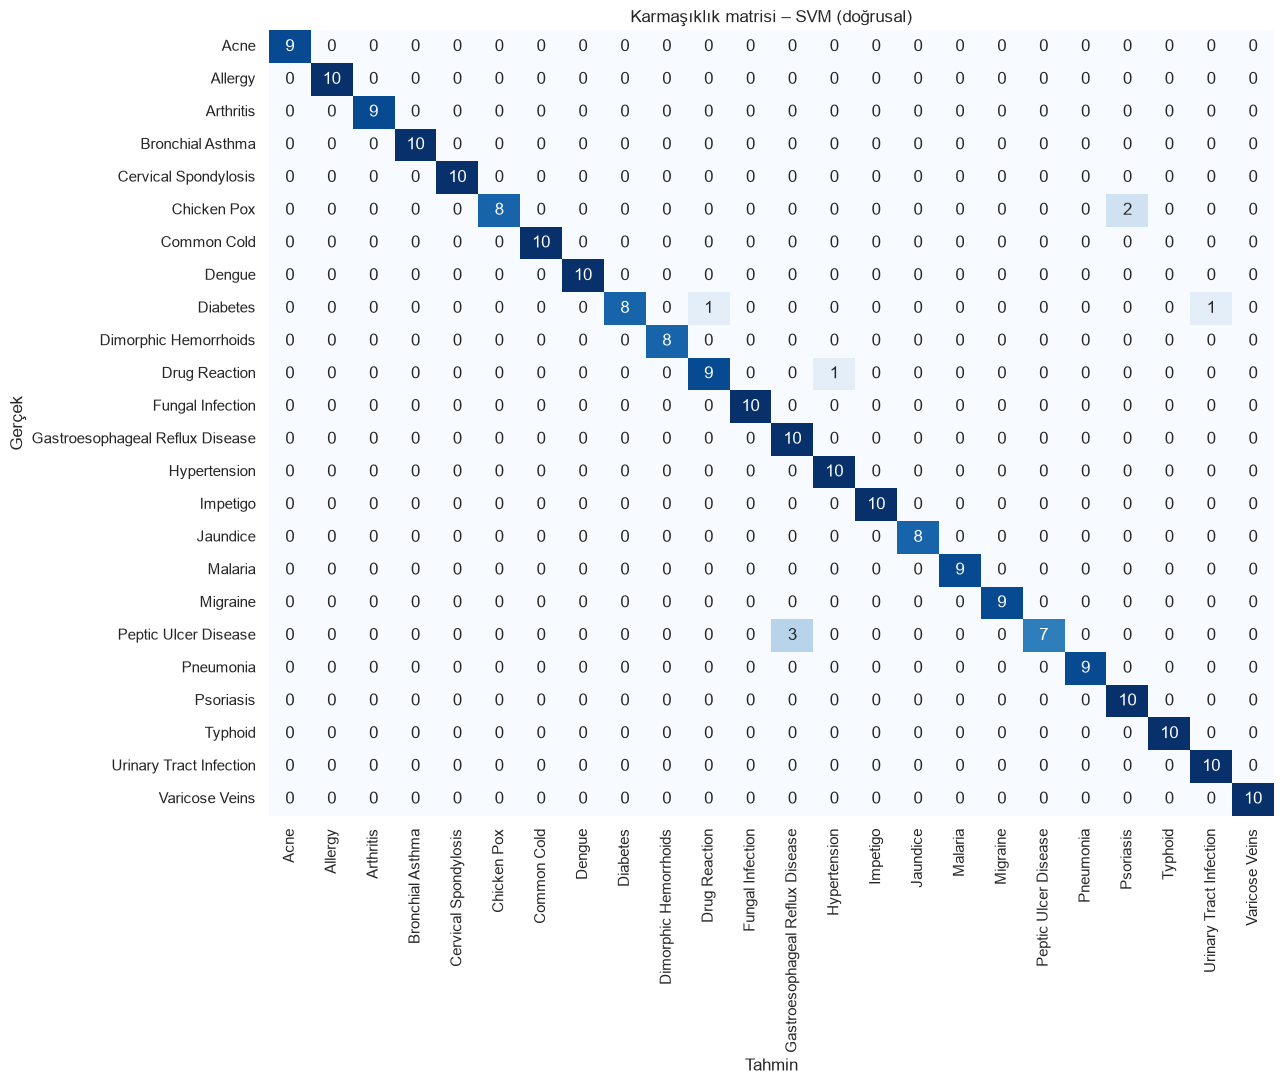

,Gerçek,Tahmin,Sayı
0,Peptic Ulcer Disease,Gastroesophageal Reflux Disease,3
1,Chicken Pox,Psoriasis,2
2,Diabetes,Urinary Tract Infection,1
3,Drug Reaction,Hypertension,1
4,Diabetes,Drug Reaction,1


In [11]:
from sklearn.metrics import confusion_matrix

final_model = en_iyi_modeller[final_ad]
tahmin = final_model.predict(X_test)
etiketler = sorted(y.unique())
cm = confusion_matrix(y_test, tahmin, labels=etiketler)

plt.figure(figsize=(13, 11))
sns.heatmap(cm, xticklabels=etiketler, yticklabels=etiketler, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("Tahmin"); plt.ylabel("Gerçek"); plt.title(f"Karmaşıklık matrisi – {final_ad}")
plt.tight_layout(); plt.savefig(FIG + "belirti_05_karmasiklik_matrisi.png", dpi=150); plt.show()

hatalar = pd.DataFrame({"Gerçek": y_test, "Tahmin": tahmin})
hatalar = hatalar[hatalar["Gerçek"] != hatalar["Tahmin"]].value_counts().rename("Sayı").reset_index()
hatalar.to_csv(TAB + "belirti_karistirilan_hastaliklar.csv", index=False)
hatalar.head(10)

In [13]:
yeni = ["I have a high fever, chills and my whole body aches, I sweat a lot at night",
        "my skin is itchy with red scaly patches on my elbows",
        "I feel a burning pain in my chest after eating and sour taste in my mouth",
        "I have to pee very often and it burns when I urinate",
        "my eyes and skin have turned yellow and my urine is dark"]
for c in yeni:
    p = final_model.predict_proba([temizle(c)])[0]
    sira = np.argsort(p)[::-1][:3]
    print(c)
    print("   →", ", ".join(f"{final_model.classes_[i]} (%{p[i]*100:.0f})" for i in sira), "\n")

I have a high fever, chills and my whole body aches, I sweat a lot at night
   → Dengue (%46), Malaria (%6), Typhoid (%6) 

my skin is itchy with red scaly patches on my elbows
   → Psoriasis (%70), Fungal Infection (%12), Chicken Pox (%2) 

I feel a burning pain in my chest after eating and sour taste in my mouth
   → Gastroesophageal Reflux Disease (%91), Peptic Ulcer Disease (%4), Hypertension (%1) 

I have to pee very often and it burns when I urinate
   → Urinary Tract Infection (%100), Psoriasis (%0), Jaundice (%0) 

my eyes and skin have turned yellow and my urine is dark
   → Jaundice (%51), Allergy (%8), Psoriasis (%7) 



## Modelin kaydedilmesi
Chatbot kullanıcıdan ham cümle alacak. Bu yüzden metin temizleme adımı da modelin içine eklenir ve tüm veriyle yeniden eğitilir.

In [14]:
import joblib
from sklearn.base import clone
from sklearn.preprocessing import FunctionTransformer

final_tum = Pipeline([("temizle", FunctionTransformer(toplu_temizle))] + clone(final_model).steps)
final_tum.fit(silver["text"], silver["label"])
joblib.dump({"model": final_tum, "model_adi": final_ad}, "../models/belirti_modeli.pkl")
print("Kaydedildi: models/belirti_modeli.pkl  (" + final_ad + ")")
print("Test:", final_tum.predict(["I have a terrible headache and light hurts my eyes"]))

Kaydedildi: models/belirti_modeli.pkl  (SVM (doğrusal))
Test: ['Allergy']
